# Blind retrieval, light curve `lc_a`: a giant planet on a one-year orbit

This is one of six light curves of a **blind injection-retrieval test**: Nicholas Jannsen simulated PLATO-like
light curves, some (or none) with an exomoon, and sent us the light curves only. We do not know what was injected,
nor which instrumental effects or stellar signals were added. Here we analyse `lc_a` with Pandora, from the raw data
to a Bayes factor and a physical interpretation, in the order one would do it with real data.

We use two routes for the stellar and instrumental trends, and compare them:

- **A, biweight:** detrend the light curve with a robust filter (wotan's biweight, transits masked), then fit the
  transit model with white-noise errors;
- **B, simultaneous GP:** fit the raw flux as transit model + Gaussian process + white noise.

For each route we run the fast detection test `pandora.detect` (seconds) and the full fit `pandora.NestedSampler`
(minutes on a GPU), which gives the evidence of the planet-only and the planet+moon model and the posteriors.

**Contents:** 1. the data and their problems; 2. a model-free look at the transits; 3. priors; 4. cleaning;
5. route A (biweight); 6. route B (GP); 7. the evidence; 8. figures; 9. the physics of the planet+moon solution;
10. further checks (audit, injection-retrieval tests); 11. assessment and learnings.

## 0. Set-up

This notebook needs `pandoramoon` with its optional parts (`pip install "pandoramoon[gpu,plots,search]"` and, for the
GPU, `pip install "numba-cuda[cu13]"`), `pandas` and `pyarrow` (to read the feather files). `blind.py` (in this folder)
holds the helper functions shared by the six notebooks: loading, data checks, the noise model, the two light-curve
preparations and the plots. Every Pandora call is in this notebook.

The full fits run on the GPU (`DEVICE = "gpu"`); `DEVICE = "cpu"` gives the same results, slower. `THREADS` limits the
CPU cores (detection, the planet-only fit, the GP profile). Every fit is stored in `results/`. With `REFIT = False`
(default) the notebook reads the stored fits (`blind.load_fit`: the results Pandora wrote, checked against the current
data and priors; no sampler, no GPU) and runs in a few minutes; it fits only what is not stored yet. With
`REFIT = True` it runs the fits again.

In [1]:
%matplotlib inline
import time as timer
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = [12, 4]

import pandoramoon as pandora
from pandoramoon.gp import GP
import blind

NAME = "a"                # light curve lc_a.ftr
DEVICE = "gpu"            # "cpu" works too (slower)
import os
THREADS = int(os.environ.get("BLIND_THREADS", 5))     # CPU threads (detect, planet-only fits, GP profile)
# REFIT = False: read the stored fits from results/ (no sampler, no GPU); fit only what is not stored yet.
# REFIT = True: run the full fits again (resume="resume" reuses Pandora's stored runs where the data are unchanged)
REFIT = bool(int(os.environ.get("BLIND_REFIT", "0")))
RESULTS = f"results/lc_{NAME}"
from pandoramoon.version import PANDORA_VERSIONING
print("pandoramoon", PANDORA_VERSIONING)

pandoramoon 2.1


## 1. The data, and what is wrong with them

A blind test: we were given the light curve only. The files hold time [s] and flux normalised to 1. Before any fit
we look for the problems a real (or a realistically simulated) light curve has: gaps, jumps between segments, ramps
after gaps, outliers and flares, and a noise level that changes with time. `blind.data_checks` prints a table per
continuous segment; `blind.plot_checks` shows the light curve, the noise level over time, and the flux in the first
and last three days of every segment.

104044 points, cadence 600.004 s, span 729.48 d, 8 segments
segment      start      end       N   mean [ppm]  sigma [ppm/cadence]  slope [ppm/d]
   0       0.00     90.31   13005       -0.7         61.7            +0.027
   1      91.31    181.62   13006       +1.9         70.2            -0.013
   2     182.62    272.93   13005       -2.0         54.8            +0.003
   3     273.93    364.24   13006       +1.0         50.3            -0.019
   4     365.24    455.56   13006       -0.6         76.8            +0.013
   5     456.56    546.86   13005       +1.5         57.7            -0.019
   6     547.86    638.17   13006       -1.4         51.9            -0.019
   7     639.17    729.48   13005       +1.7         45.0            -0.012
jumps across the gaps (12 h after minus 12 h before) [ppm]: +30±11, +28±11, +59±13, +80±12, +37±13, +27±11, +48±9
first 1 d of each segment vs its middle: mean +9.6 ppm (each: -3, +1, +4, +20, +37, +3, +7, +8)
last  1 d of each segment vs its midd

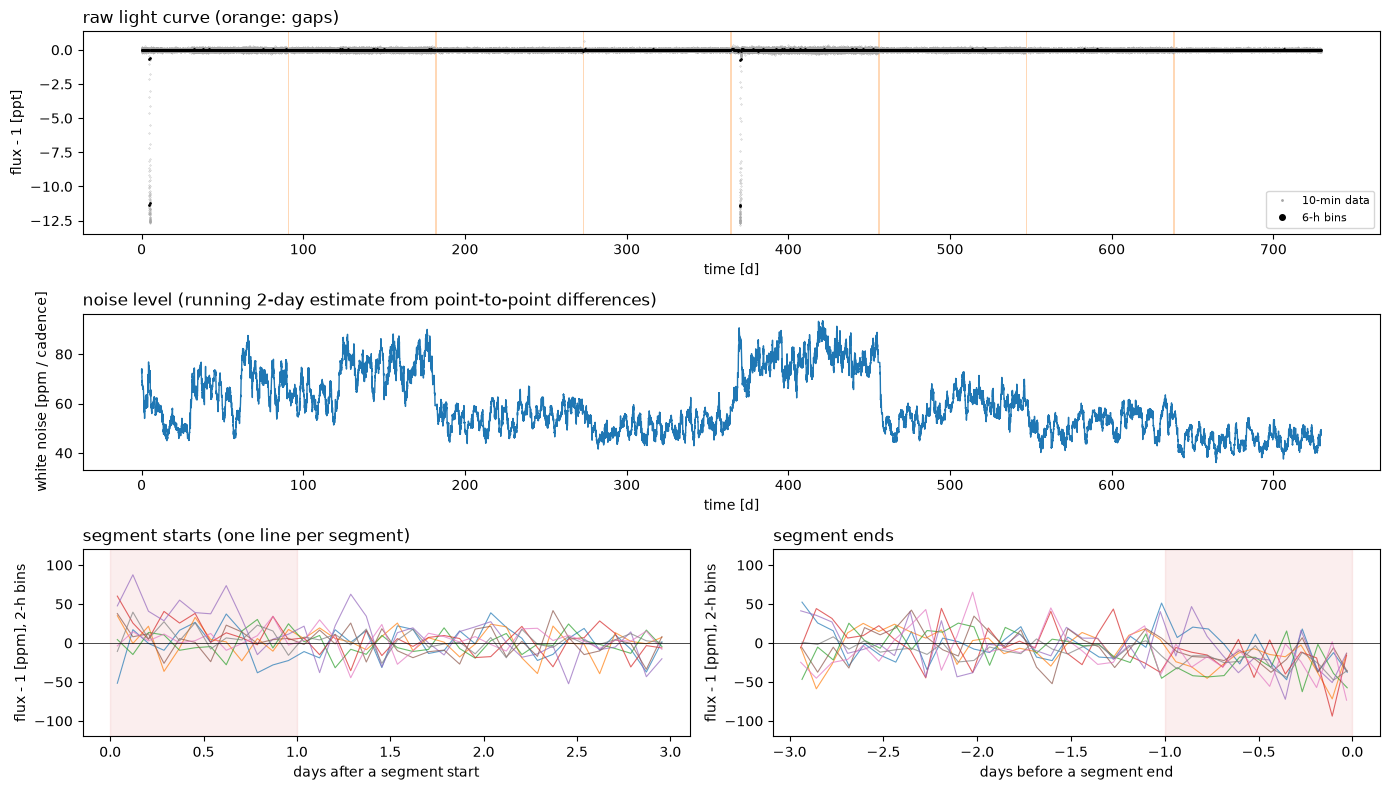

In [2]:
t, f = blind.load(NAME)
checks = blind.data_checks(t, f)
blind.plot_checks(t, f, checks)
plt.show()

**What the checks show**

- **Sampling.** 104 044 points, one every 600.004 s (10 min), over 729.5 days. The light curve has 8 segments of
  91.3 days separated by 1-day gaps: PLATO turns by 90° every three months, and the simulation leaves a day out at
  each turn.
- **No offsets between segments.** Each segment's mean is within ±2 ppm of 1, so the light curve was normalised per
  segment.
- **Ramps at the segment edges.** The flux is higher than average in the first day after a gap and lower in the
  last day before it, by 10–40 ppm (bottom panels). Across a gap the level jumps up by 27–80 ppm. All six light
  curves of this test show the same pattern, so it is instrumental or a processing artefact, not the star. It is
  small, but it is the size of an Earth-size moon's dip, so we leave the edge days out (section 4).
- **The noise changes with time** (middle panel): from 45 to 77 ppm per 10-min point between segments, and by ±20 %
  within them. The segments starting at days 91 and 365 are the noisiest. The second transit (day 370) falls into
  such a segment (~80 ppm), the first (day 5) into a quieter one (~60 ppm). A fit with one error bar for all points
  would give the second transit too much weight. We use a running local noise level σ(t) as the error bars.
- **The noise is not white at the shortest lag**: neighbouring points are correlated (+0.11), points further apart
  are not. This is typical of time series that were resampled or co-added. The rms of averages over 30–60 min is
  ~15 % higher than for white noise; that is what the red-noise factor β (route A) and the GP (route B) describe.
  lc_a's noise also has slightly heavier tails than a Gaussian (excess kurtosis +0.26).
- **Outliers:** a handful of single points beyond 5σ, upwards and downwards. No flares, no spots, no stellar
  variability: on time scales of days the star is flat to a few ppm.

## 2. A first look at the transits (no model)

We find the transits without a model: runs of points more than 5σ below 1, their mid-times (half-depth crossings),
the period and epoch of a linear ephemeris, the depth and the total duration T14 (from the stack of all transits).
These numbers only centre the priors and set the windows; the fits determine them properly.

In [3]:
ft = blind.find_transits(t, f, checks["sigma"])
T14 = blind.transit_duration(t, f, ft, checks["sigma"])
P, T0 = ft["P"], ft["T0"]
print(f"{len(ft['tmid'])} transits at t = {np.round(ft['tmid'], 3)} d")
print(f"P = {P:.5f} d, T0 = {T0:.5f} d, depth = {1e6 * ft['depth']:.0f} ppm, T14 = {24 * T14:.2f} h")
oc = 1440 * (ft["tmid"] - (T0 + P * ft["epoch"]))
print("mid-times minus the linear ephemeris [min]:", np.round(oc, 2))
print("half-depth durations [min]:", np.round(1440 * ft["dur_half"], 1))
HALF_LOOK = min(1.0, 0.45 * P)          # half-width of the plots below [d]

2 transits at t = [  4.999 370.247] d
P = 365.24804 d, T0 = 4.99892 d, depth = 12534 ppm, T14 = 14.00 h
mid-times minus the linear ephemeris [min]: [0. 0.]
half-depth durations [min]: [741.5 731.7]


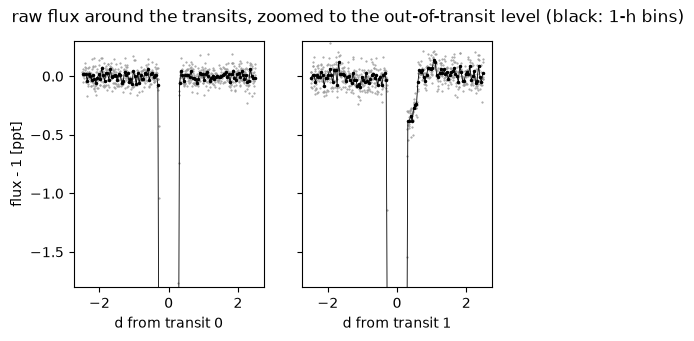

In [4]:
n_show = min(len(ft["tmid"]), 8)
fig, axs = plt.subplots(1, n_show, figsize=(2.2 * n_show + 1, 3.2), sharey=True, squeeze=False)
for k, ax in enumerate(axs[0]):
    tc = ft["tmid"][k]
    m = np.abs(t - tc) < 2.5
    ax.plot(t[m] - tc, 1e3 * (f[m] - 1), ".", ms=1, color="0.6")
    xb, yb, _ = blind.binned(t[m] - tc, f[m], 1 / 24)
    ax.plot(xb, 1e3 * (yb - 1), "k.-", ms=3, lw=0.6)
    ax.set_ylim(-0.12 * 1e3 * ft["depth"] - 0.3, 0.3)
    ax.set_xlabel(f"d from transit {ft['epoch'][k]}")
axs[0, 0].set_ylabel("flux - 1 [ppt]")
plt.suptitle("raw flux around the transits, zoomed to the out-of-transit level (black: 1-h bins)", x=0.01, ha="left")
plt.show()

**Do the transits differ?** Before any model: we align the transits on the linear ephemeris and subtract them from
each other (two transits) or from their median (more transits). A moon shows up as dips that move from transit to
transit, and as changes of the transit's timing and duration (the planet wobbles around the planet-moon
barycentre). Spot crossings would show as short bumps *inside* the transit, instrumental steps as offsets.

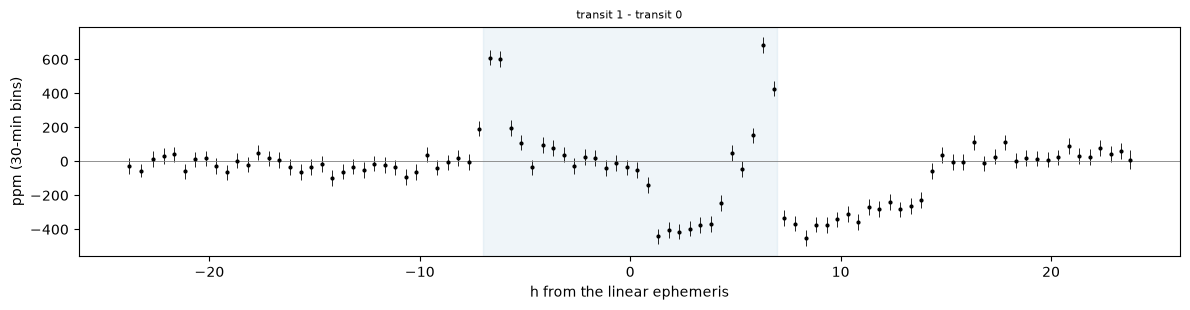

In [5]:
grid = np.arange(-HALF_LOOK, HALF_LOOK, 600 / 86400)
stack = np.array([np.interp(grid, t[np.abs(t - (T0 + P * e)) < HALF_LOOK + 0.1] - (T0 + P * e),
                            f[np.abs(t - (T0 + P * e)) < HALF_LOOK + 0.1]) for e in ft["epoch"]])
ref = stack[0] if len(stack) == 2 else np.median(stack, axis=0)
show_e = range(1, 2) if len(stack) == 2 else range(len(stack))
n_cols = 1 if len(stack) == 2 else min(len(stack), 4)
n_rows = int(np.ceil(len(show_e) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(12 if n_cols == 1 else 3.3 * n_cols, 3.2 * n_rows if n_cols == 1
                        else 2.2 * n_rows), sharex=True, sharey=True, squeeze=False)
sig_med = np.median(checks["sigma"])
for ax, i in zip(axs.flat, show_e):
    xb, db, nb = blind.binned(grid * 24, stack[i] - ref, 0.5)
    ax.errorbar(xb, 1e6 * db, 1e6 * sig_med * np.sqrt(2) / np.sqrt(nb), fmt="o", ms=2, color="k", elinewidth=0.6)
    ax.axhline(0, color="0.5", lw=0.6)
    ax.axvspan(-12 * T14, 12 * T14, color="C0", alpha=0.07)
    ax.set_title(f"transit {ft['epoch'][i]} - " + ("transit 0" if len(stack) == 2 else "median"), fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel("h from the linear ephemeris")
for ax in axs[:, 0]:
    ax.set_ylabel("ppm (30-min bins)")
for ax in axs.flat[len(show_e):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Two transits, one year apart.** The planet transits at days 5.0 and 370.2: a period of 365.25 days (a time
distance of two transits is all we have: the period could also be 365.25 / n days if transits fell into gaps, but the
data have no gaps at the right places). The transit is 12 500 ppm deep and lasts 14 hours: a Jupiter-size planet
around a Sun-like star at about 1 AU.

**The two transits are not the same**, and we can see why without a model (the difference plot):

1. From +1.5 h to about +14 h after mid-transit, the second transit is **~400 ppm deeper**, also after the
   planet's egress (+7 h). That is a dip of ~12 hours, the length of a transit at this orbital speed: an object
   about 0.02 stellar radii in size crossing the star some 8 hours behind the planet.
2. At ingress (−6.5 h) and egress (+6.5 h) the difference shows two **+600 ppm spikes**: the second transit starts
   later and ends earlier: it is **~10 min shorter** (half-depth durations 741.5 and 731.7 min). A planet with a moon wobbles around the planet-moon barycentre;
   its speed at transit changes from epoch to epoch, and so does the transit duration (TDV).
3. In the first transit there is no extra dip anywhere within ±4 days (overview plots). If a moon is there, it was in
   front of or behind the planet, i.e. hidden in the planet's shadow at that time.

This is what a moon does. It could also be a coincidence of an instrumental dip after one transit and a duration
change from something else, which is what the fits and the jackknife test.

## 3. Priors, and how far from the planet a moon can be

We use Pandora's `default_priors` (the priors the detection test was calibrated with), centred on the ephemeris
above. The moon priors are: radius 0.1–0.7 × the planet's, period up to 0.19 × the planet's period (the prograde
stability limit at ~0.48 Hill radii), mass up to half the planet's, all orientations.

The moon can transit up to `reach` days before or after its planet: its largest orbit (the longest prior period,
the heaviest prior planet) divided by the planet's speed. The fit windows must cover the transit and this reach,
otherwise a moon's dip can fall outside the data.

In [6]:
r_planet = float(np.sqrt(ft["depth"]))      # first guess of R_planet / R_star (limb darkening makes it ~5 % too large)
priors = pandora.default_priors(t0_bary=round(T0, 2), per_bary=P, r_planet=r_planet)   # Jupiter-mass planet (default)
SKIP_STACK = [(0.2, 0.75)]     # section 8.1b: leave the moon's dip after the second transit out of the stack

In [7]:
for name, prior in priors.items():
    print(f"  {name:16s} {prior}")
reach = blind.moon_reach(P, priors["per_moon"].hi, priors["M_planet"].hi)
HALF = reach["reach_days"] + T14          # half-width of the fit windows [d]
print(f"largest moon orbit {reach['a_moon_max']:.2f} R_star = {reach['reach_days']:.2f} d of planet motion "
      f"(Hill radius {reach['r_hill']:.1f} R_star = {reach['hill_days']:.2f} d); fit windows: +-{HALF:.2f} d")

  q1               Uniform(lo=0.0, hi=1.0)
  q2               Uniform(lo=0.0, hi=1.0)
  R_star           Uniform(lo=557073600.0, hi=835610400.0)
  per_bary         Uniform(lo=364.5175442424462, hi=365.97853640373853)
  a_bary           LogUniform(lo=85.95942840280485, hi=537.2464275175303)
  r_planet         Uniform(lo=0.05597866990120302, hi=0.16793600970360906)
  b_bary           Uniform(lo=0.0, hi=1.0)
  t0_bary          5.0
  t0_bary_offset   Uniform(lo=-0.05, hi=0.05)
  M_planet         Uniform(lo=9.49065e+26, hi=2.847195e+27)
  r_moon           Uniform(lo=0.011195733980240603, hi=0.07837013786168422)
  per_moon         Uniform(lo=0.0, hi=69.397)
  tau_moon         Uniform(lo=0.0, hi=1.0)
  Omega_moon       Uniform(lo=0.0, hi=180.0)
  i_moon           Uniform(lo=0.0, hi=180.0)
  M_moon           Uniform(lo=0.0, hi=9.49065e+26)
largest moon orbit 8.00 R_star = 2.16 d of planet motion (Hill radius 16.8 R_star = 4.54 d); fit windows: +-2.75 d


**Priors.** The planet is Jupiter-size, so the default planet mass prior (0.5–1.5 Jupiter masses) is reasonable.
The period prior (±0.002 P = ±0.7 d) and the epoch prior (±0.05 d) are wide compared with what two transits
determine. The moon priors are the defaults: r_moon 0.011–0.078 stellar radii (1.2–8.5 Earth radii for a Sun-like
star), periods up to 69 days, masses up to half the planet's.

**Windows.** A moon on the widest orbit the prior allows (69-day period around a 1.5 Jupiter-mass planet: 8 stellar
radii) can transit up to 2.2 days before or after the planet. With T14 that gives fit windows of ±2.75 days around
each transit: 1581 points. The full Hill sphere (4.5 days) is wider, but orbits beyond ~0.5 Hill radii are
unstable, and the prior's period limit (0.19 × P) is that stability limit.

## 4. Noise near the transits, segment edges and outliers

Three decisions, the same for both routes:

- **The noise level near the transits.** The running estimate of section 1 uses differences of neighbouring points.
  A deep transit's ingress and egress are steep steps that make large differences; they raise the running median by
  15–20 % within a day of a deep transit, exactly where the error bars matter. (We found this only after a first
  round of fits: their errors were too large near the transits, so their Bayes factors were too small.) So we
  estimate it again with the transits left out and interpolate across them.

- **Segment edges:** the flux drifts by tens of ppm in the first and last day of each segment (section 1). We leave
  out 1 day at each segment edge (2 % of the data). This affects only transit windows that touch a gap.
- **Outliers and flares:** `GP.fit(..., clip=True)` flags points above 4σ everywhere (flares), below 5σ outside the
  transit windows, and isolated one-cadence dips inside them, against the GP's own prediction. We fit the GP's
  hyperparameters here (section 6 explains them) and use its flags in both routes.

In [8]:
# the white-noise level near the transits: the running estimate of section 1 with the transits left out
in_transit = blind.phase_distance(t, T0, P) < 0.5 * T14 + 0.02
sigma = blind.local_sigma(t, f, mask=in_transit)
near = (blind.phase_distance(t, T0, P) < 0.5 * T14 + T14) & ~in_transit     # within one T14 of the transits
print(f"noise near the transits: {1e6 * np.median(sigma[near]):.1f} ppm per cadence; the estimate with the "
      f"transits included was {100 * (np.median(checks['sigma'][near] / sigma[near]) - 1):+.0f} % higher there")
edges = blind.edge_mask(t, edge=1.0)
t_start = timer.time()
# cache: GP.fit's last digits differ between CPUs; the stored hyperparameters make the data bit-identical on any
# machine, so the stored fits below are reused (resume) instead of refitted
gp, gpw, outliers = blind.prepare_gp(t, f, sigma, T0, P, HALF, bad=edges,
                                     kernel="sho", baseline="offset", gap=0.5, clip=True,
                                     cache=f"{RESULTS}/gp_hyper.npz")
bad = edges | outliers
print(f"GP hyperparameters ({'stored' if timer.time() - t_start < 1 else 'GP.fit'}, {timer.time() - t_start:.0f} s): {gp}")
print(f"left out: {edges.sum()} points at segment edges, {outliers.sum()} outliers / flares at t =",
      np.round(t[outliers], 2))
in_win = blind.phase_distance(t, T0, P) < HALF
print(f"outliers inside the fit windows: {(outliers & in_win).sum()}")

noise near the transits: 63.2 ppm per cadence; the estimate with the transits included was +23 % higher there
GP hyperparameters (stored, 0 s): GP(amp=2.02757e-05, tau=0.00694449, Q=0.707107, err_scale=0.995559, baseline='offset', gap=0.5)
left out: 2304 points at segment edges, 9 outliers / flares at t = [  1.91  68.62  82.22 291.9  368.33 399.8  424.64 512.59 555.81]
outliers inside the fit windows: 1


**Cleaning.** Near the transits the noise estimate with the transits included was 23 % too high (63 ppm per point
without them); our first round of fits used the too-high values. The segment edges cost 2304 points (2 %), none of them
in a fit window (both transits are 5 days after a segment start). The GP's clipping flags 9 single points, most of them
4–6σ above the trend (single cadences, not flares: the tails of the noise). One of them lies in a fit window (day 368.3,
2 days before the second transit). We leave all of them out in both routes.

## 5. Route A: biweight detrending + white-noise fit

The classical route. `pandora.prepare_lightcurve` detrends with wotan's robust `biweight`: the transits are masked
over 1.0 × T14 and the trend is a robust running mean over a window of 4.0 × T14 (Pandora's defaults, from a study of
300 injected moons in real Kepler data). It returns the data in the fit windows (here ±HALF around each transit).

**Error bars.** `prepare_lightcurve` measures one noise level for the whole light curve. Our noise changes with time
(section 1), and it measures β on only ~100 bins next to the transits, where a single noisy bin can change it by
20 %. We replace its errors with the local white noise σ(t) (section 4) times a red-noise factor β measured on all
detrended data outside the windows after dividing by σ(t) (bins of T14 / 4).

In [9]:
bw = blind.prepare_biweight(t, f, sigma, T0, P, T14, HALF, bad=bad)
print(f"{len(bw['time'])} points in {len(bw['epochs'])} fit windows")
print(f"prepare_lightcurve's own errors: one sigma = {1e6 * bw['sigma']:.1f} ppm, beta = {bw['beta']:.2f} "
      f"(beta from ~100 bins next to the transits)")
print(f"local errors: sigma(t) x beta, beta = {bw['beta_local']:.3f}; errors {1e6 * bw['flux_err'].min():.0f} ... "
      f"{1e6 * bw['flux_err'].max():.0f} ppm")
w_tr = blind.phase_distance(bw["time_all"], T0, P) < HALF
print(f"biweight trend inside the windows: {1e6 * (np.nanmin(bw['trend'][w_tr]) - 1):+.0f} ... "
      f"{1e6 * (np.nanmax(bw['trend'][w_tr]) - 1):+.0f} ppm")
like_bw = pandora.Likelihood(bw["time"], bw["flux"], bw["flux_err"], epoch_distance=P, hill_sphere_threshold=1.0)

1581 points in 2 fit windows
prepare_lightcurve's own errors: one sigma = 55.5 ppm, beta = 1.15 (beta from ~100 bins next to the transits)
local errors: sigma(t) x beta, beta = 1.150; errors 58 ... 86 ppm
biweight trend inside the windows: -31 ... +27 ppm


### 5.1 Detection: `pandora.detect`

The fast test: one short nested-sampling run of the planet-only model and a few short runs of the planet+moon model.
It returns Δln Z = ln Z(planet+moon) − ln Z(planet only) (noisy, ±0.5) and the **epoch jackknife**: the moon model's
fit improvement Δχ² per transit. A light curve is a *candidate* if Δln Z > 3 and the moon is still significant without
the transit that carries most of it (Δχ² ≥ 18 in the remaining transits). Seconds of CPU time.

In [10]:
det_bw = pandora.detect(like_bw, priors, verbose=True, threads=THREADS)
print("moon (median, 16 %, 84 %):", {k: tuple(round(x, 4) for x in v) for k, v in det_bw["moon"].items()})
print("jackknife dchi2 per transit:", dict(zip(det_bw["jackknife"]["epochs"],
                                                np.round(det_bw["jackknife"]["dchi2_epochs"], 1))))

Pandora: compiling numerical code (first use after installation or an update can take a few minutes; the result is cached) ...


detect: dlnZ = +777.90 +- 1.43 (threshold 3.0); jackknife: 492.4 without the strongest transit (need >= 18.0); candidate: True
moon (median, 16 %, 84 %): {'per_moon': (6.4655, 6.0372, 6.9577), 'r_moon': (0.0187, 0.0185, 0.0189), 'i_moon': (116.5356, 114.7566, 118.0426), 'M_moon/M_planet': (0.0186, 0.0181, 0.0192)}
jackknife dchi2 per transit: {0: np.float64(492.4), 1: np.float64(1123.5)}


### 5.2 The full fit: `pandora.NestedSampler` on the GPU

Both models, with checked evidences (±0.2 in ln Z) and posteriors. The planet-only model is fitted on the CPU
(importance sampling), the planet+moon model on the GPU. 10-min cadences are integrated over 5 sub-exposures
(`supersampling="auto"`). The sampler adds runs, live points and chain length until its own checks pass.

In [11]:
t_start = timer.time()
if REFIT or not blind.fit_stored(f"{RESULTS}/biweight"):
    s_bw = pandora.NestedSampler(like_bw, priors, device=DEVICE, threads=THREADS, log_dir=f"{RESULTS}/biweight",
                                 resume="resume", verbose=False)
    r_bw = s_bw.run(progress=False)
else:
    s_bw, r_bw = blind.load_fit(like_bw, priors, f"{RESULTS}/biweight")     # the stored fit, read back
rec_bw = blind.run_record(f"{RESULTS}/biweight", r_bw)
print(f"wall time of this cell: {(timer.time() - t_start) / 60:.1f} min; the planet+moon fit took "
      f"{rec_bw['wall'] / 60:.1f} min ({rec_bw['ncall'] / 1e9:.1f} G likelihood calls) when it ran ({rec_bw['date']})")
s_bw.print_results()

wall time of this cell: 0.0 min; the planet+moon fit took 31.3 min (19.8 G likelihood calls) when it ran (2026-11-21T11:31:17)
planet + moon: logZ = -890.162 +- 0.200   (checks NOT passed; 66 runs x 2000 live, nsteps 128, 19,791,898,617 calls, 1880 s)
    q1              : 0.394197 -0.0144 +0.0149   (mean 0.394436, sd 0.0147)
    q2              : 0.380535 -0.0139 +0.0144   (mean 0.380751, sd 0.0141)
    R_star          : 7.05346e+08 -8.17e+07 +6.02e+07   (mean 6.97486e+08, sd 6.35e+07)
    per_bary        : 365.25 -0.000207 +0.000211   (mean 365.25, sd 0.000209)
    a_bary          : 214.954 -0.245 +0.194   (mean 214.925, sd 0.246)
    r_planet        : 0.0999197 -8.08e-05 +8.33e-05   (mean 0.0999212, sd 8.34e-05)
    b_bary          : 0.0262419 -0.0185 +0.0278   (mean 0.0305699, sd 0.0225)
    t0_bary_offset  : -5.87217e-05 -0.000105 +0.000104   (mean -5.89234e-05, sd 0.000104)
    M_planet        : 2.22004e+27 -6.44e+26 +4.49e+26   (mean 2.14378e+27, sd 4.86e+26)
    r_moon         

## 6. Route B: the raw flux with a simultaneous GP

Instead of detrending first, we fit the raw (normalised) flux as **transit model + Gaussian process + white noise**
(`Likelihood(..., gp=gp)`). The GP is an SHO kernel (Q = 1/√2) whose hyperparameters (amplitude, time scale, a factor
on the white noise) were fitted in section 4 by maximum likelihood on the data *outside* the fit windows. The white
noise is σ(t) × err_scale, so the changing noise level is included. `baseline="offset"` with `gap=0.5` gives each
data segment (here: each transit window) its own constant level, marginalised analytically.

The hyperparameters are held fixed during the fit. A planet-only model with a freer GP could explain part of a moon's
dip as noise, so with fixed hyperparameters a real moon's Bayes factor comes out too high. `gp_profile=True` refits
them for each model after the fit and reports the **conservative** Bayes factor `dlogz_conservative`: we quote that
one. (We call it as `blind.gp_profile_cached(s_gp, r_gp)` after the fit: the same computation, stored so that a
second run of the notebook reads it back instead of repeating the refits.)

In [12]:
print(gp)
print(f"GP amplitude {1e6 * gp.amp:.1f} ppm, time scale {24 * 60 * gp.tau:.1f} min, white-noise factor {gp.err_scale:.3f}")
like_gp = pandora.Likelihood(gpw["time"], gpw["flux"], gpw["flux_err"], epoch_distance=P, hill_sphere_threshold=1.0,
                             gp=gp)
det_gp = pandora.detect(like_gp, priors, verbose=True, threads=THREADS)
print("moon (median, 16 %, 84 %):", {k: tuple(round(x, 4) for x in v) for k, v in det_gp["moon"].items()})
print("jackknife dchi2 per transit:", dict(zip(det_gp["jackknife"]["epochs"],
                                                np.round(det_gp["jackknife"]["dchi2_epochs"], 1))))

GP(amp=2.02757e-05, tau=0.00694449, Q=0.707107, err_scale=0.995559, baseline='offset', gap=0.5)
GP amplitude 20.3 ppm, time scale 10.0 min, white-noise factor 0.996


detect: dlnZ = +759.21 +- 1.50 (threshold 3.0); jackknife: 492.1 without the strongest transit (need >= 18.0); candidate: True
moon (median, 16 %, 84 %): {'per_moon': (5.411, 4.8375, 5.9388), 'r_moon': (0.0182, 0.018, 0.0185), 'i_moon': (121.6381, 118.9355, 124.2495), 'M_moon/M_planet': (0.0179, 0.0172, 0.0185)}
jackknife dchi2 per transit: {0: np.float64(492.1), 1: np.float64(1109.1)}


**The GP of this light curve is not stellar variability.** `GP.fit` puts the time scale at its lower bound, 10 min =
one cadence, with an amplitude of 20 ppm. The star has no variability on time scales of hours to days that the fit
could find. What the GP describes is the correlation of neighbouring points (section 1): an extra ~20 ppm that is
shared by adjacent cadences. For the fit, this matters in two ways. The white noise is σ(t) × 0.996, as the running
estimate says, and a dip that lasts hours is not explained away by the GP, because the GP forgets within ~10 min.

In [13]:
t_start = timer.time()
if REFIT or not blind.fit_stored(f"{RESULTS}/gp"):
    s_gp = pandora.NestedSampler(like_gp, priors, device=DEVICE, threads=THREADS, log_dir=f"{RESULTS}/gp",
                                 resume="resume", verbose=False)
    r_gp = s_gp.run(progress=False)
else:
    s_gp, r_gp = blind.load_fit(like_gp, priors, f"{RESULTS}/gp")     # the stored fit, read back
# the conservative Bayes factor (= NestedSampler(..., gp_profile=True)); stored in gp_profile.json and read back
# when the notebook runs again (gp_profile itself would redo its refits)
blind.gp_profile_cached(s_gp, r_gp)
rec_gp = blind.run_record(f"{RESULTS}/gp", r_gp)
print(f"wall time of this cell: {(timer.time() - t_start) / 60:.1f} min; the planet+moon fit took "
      f"{rec_gp['wall'] / 60:.1f} min ({rec_gp['ncall'] / 1e9:.1f} G likelihood calls) when it ran ({rec_gp['date']})")
s_gp.print_results()

wall time of this cell: 0.0 min; the planet+moon fit took 76.0 min (34.6 G likelihood calls) when it ran (2026-11-21T13:14:19)
planet + moon: logZ = -1149.757 +- 0.199   (checks NOT passed; 59 runs x 2000 live, nsteps 256, 34,644,352,882 calls, 4557 s)
    q1              : 0.391001 -0.0141 +0.0144   (mean 0.391177, sd 0.0143)
    q2              : 0.384806 -0.0137 +0.0142   (mean 0.385065, sd 0.014)
    R_star          : 7.05773e+08 -8.29e+07 +6.16e+07   (mean 6.98101e+08, sd 6.44e+07)
    per_bary        : 365.25 -0.000203 +0.000205   (mean 365.25, sd 0.000204)
    a_bary          : 214.956 -0.242 +0.193   (mean 214.926, sd 0.243)
    r_planet        : 0.0999836 -7.98e-05 +8.24e-05   (mean 0.099985, sd 8.25e-05)
    b_bary          : 0.0262302 -0.0184 +0.0276   (mean 0.0305097, sd 0.0224)
    t0_bary_offset  : -8.76883e-05 -0.000105 +0.000106   (mean -8.74898e-05, sd 0.000106)
    M_planet        : 2.22104e+27 -6.49e+26 +4.5e+26   (mean 2.14349e+27, sd 4.88e+26)
    r_moon          :

## 7. The evidence

| | Δln Z = ln Z(planet+moon) − ln Z(planet) |
|---|---|
| > 0 | the data prefer a moon; Jeffreys' scale: 1.15 substantial, 2.3 strong, 3.45 very strong, > 4.6 decisive |
| < 0 | the planet-only model is preferred (the moon model pays an Occam penalty for its extra parameters) |

These categories assume that the noise model is right. Real (and realistically simulated) data have residual
systematics, so a moon claim needs more than a large Δln Z: the moon must be seen in more than one transit
(jackknife), both detrending routes must agree, and its parameters must make physical sense.

In [14]:
rows = [("detect, biweight", det_bw["dlnz"], det_bw["dlnz_err"], det_bw["candidate"]),
        ("detect, GP", det_gp["dlnz"], det_gp["dlnz_err"], det_gp["candidate"]),
        ("full fit, biweight", r_bw["dlogz"], r_bw["dlogzerr"], r_bw["passed"]),
        ("full fit, GP (fixed hyperparameters)", r_gp["dlogz"], r_gp["dlogzerr"], r_gp["passed"])]
if r_gp.get("dlogz_conservative") is not None:
    rows.append(("full fit, GP, conservative (gp_profile)", r_gp["dlogz_conservative"], np.nan, r_gp["passed"]))
print(f"{'':42s} {'Delta ln Z':>11s} {'+-':>6s}   {'flag':6s}  Jeffreys")
for name, d, e, flag in rows:
    print(f"{name:42s} {d:11.2f} {e:6.2f}   {str(flag):6s}  {blind.evidence_words(d)}")
print("(flag: 'candidate' for detect, 'checks passed' for the full fits)")
for lab, r in (("biweight", r_bw), ("GP", r_gp)):
    jk = r.get("jackknife") or {}
    if jk:
        print(f"{lab}: jackknife dchi2 per transit", dict(zip(jk["epochs"], np.round(jk["dchi2_epochs"], 1))),
              "| passed:", jk["passed"])
    print(f"{lab}: notes:", r["warnings"])

                                            Delta ln Z     +-   flag    Jeffreys
detect, biweight                                777.90   1.43   True    decisive
detect, GP                                      759.21   1.50   True    decisive
full fit, biweight                              810.79   0.20   False   decisive
full fit, GP (fixed hyperparameters)            802.62   0.20   False   decisive
full fit, GP, conservative (gp_profile)         162.30    nan   False   decisive
(flag: 'candidate' for detect, 'checks passed' for the full fits)
biweight: jackknife dchi2 per transit {0: np.float64(569.9), 1: np.float64(1126.4)} | passed: True
biweight: notes: ["supersampling: 5 sub-exposures per cadence (cadence 10.0 min; supersampling='auto')", 'planet + moon: convergence checks not passed (status stalled; result usable, error not guaranteed): no further escalation possible (some runs found a better solution; n_live 2000, nsteps 128); stopped with the lnZ error within lz_tol. Not met:

**All estimates favour the moon, by a wide margin.**

| | Δln Z | Jeffreys |
|---|---|---|
| `detect`, biweight / GP | +778 / +759 (± 1.5) | decisive |
| full fit, biweight | **+810.8 ± 0.2** | decisive |
| full fit, GP, hyperparameters fixed | +802.6 ± 0.2 | decisive |
| full fit, GP, hyperparameters refitted per model (conservative) | **+162.3** | decisive |

- **Both transits carry the signal** (epoch jackknife): the moon model improves χ² by ~575 in the first transit and
  by ~1100 in the second. In the second transit it is the moon's own dip; in the first, where no dip is visible, it
  is the shape and duration of the planet's transit (the moon hidden behind or in front of the planet, and the
  planet's barycentric wobble). Without the stronger transit, Δχ² ≈ 575 remains (the test needs 18).
- **The conservative GP value is ~5× smaller** than the one with fixed hyperparameters: refitted, the planet-only
  model takes a GP with ~80 ppm amplitude and a ~30-min time scale, which absorbs part of the moon's dip as correlated
  noise. 162 nats is still a Bayes factor of 10^70.
- **Both full fits stopped with status "stalled"**, not "passed": the posterior has several modes (the moon's phase
  and period, section 8.4), the sampler doubled the live points to its cap (2000) and the chains to 128–256 steps,
  and stopped once the ln Z error was within ±0.2. The evidences are uncertain by about a nat, irrelevant here.
- **A first round of fits**, with error bars that were 23 % too large near the transits (section 4), gave +568,
  +602 and +146. Correct errors raise the evidence; they do not change the moon (section 8.4).
- `detect` (10 s) came within 5 % of the full fits (31 and 76 min). Its moon summaries (periods 6.5 / 5.4 d, mass
  ratio 0.019 / 0.018) are close to, but not the same as, the full fits' (7.2 d, 0.026): a few short runs land in
  different modes of a multimodal posterior.

## 8. Figures

### 8.1 The total light curve: raw and detrended

Top: the raw flux with the biweight trend (orange), the outliers we left out (red crosses) and the segment edges
we left out (shaded). Middle: the
biweight-detrended flux (blue: the fit windows). Bottom: the raw flux minus the GP's trend: its posterior mean
given the best planet+moon model (Kalman smoother), inside the fit windows where the GP fit uses the data.

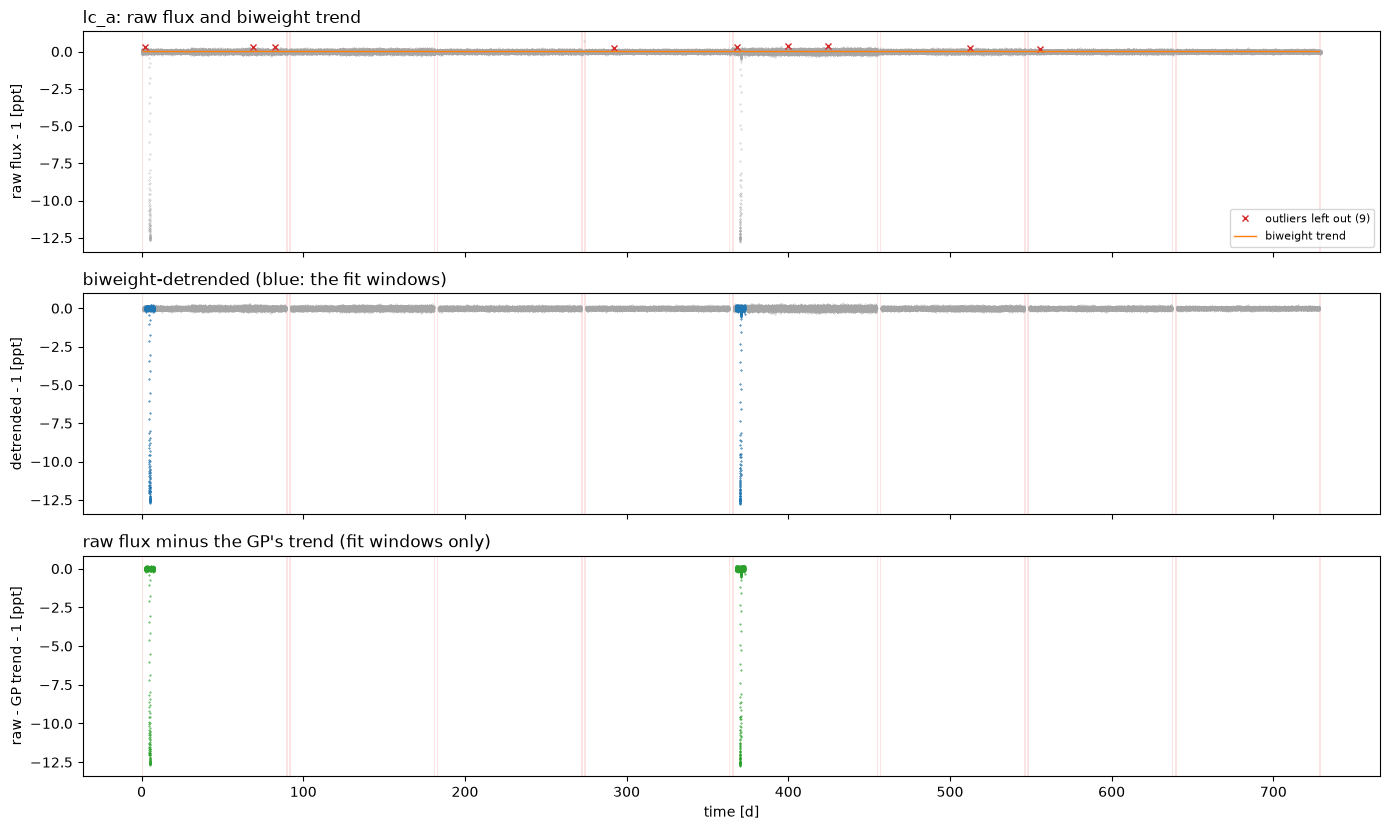

In [15]:
tr_gp = blind.gp_trends(s_gp, gp, gpw["time"], gpw["flux"], gpw["flux_err"])
blind.plot_lightcurve(t, f, T0, P, HALF, bw=bw, gp_trend=(gpw["time"], gpw["flux"], tr_gp["mu_moon"]), bad=outliers,
                      edges=edges,
                      title=f"lc_{NAME}: raw flux and biweight trend")
plt.show()

### 8.1b How well do the two detrenders follow the systematics?

The raw flux around the first transits, zoomed to the out-of-transit level (the transit itself runs off the bottom;
grey band), with the biweight trend (blue) and the GP's trend (red: its posterior mean predicted from the data outside
the transits, with its 1σ band). Below: the raw flux minus each trend in 1-h bins. Wherever the trend follows a
systematic, the residual is flat; wherever a trend follows a real signal next to the transit (a moon), that signal
disappears from the residual. In the fits the trend and the transit model are not separated this way: the biweight is
fixed before the fit, the GP is fitted together with the planet and moon.

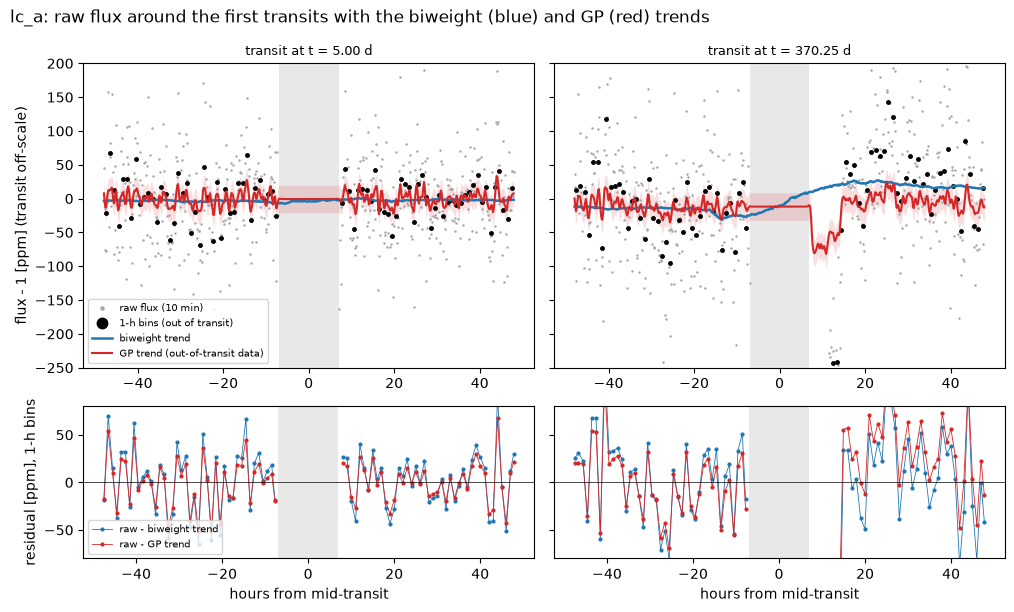

In [16]:
fig = blind.plot_detrending(t, f, bw, gp, sigma, T0, P, T14, n_transits=3, halfwidth=min(2.0, 0.45 * P), bad=bad,
                            title=f"lc_{NAME}: raw flux around the first transits with the biweight (blue) and GP (red) trends")
plt.show()

mean level in the day before the transits: -14.1 ppm; in the day after: +19.7 ppm (+- 4.3 ppm)


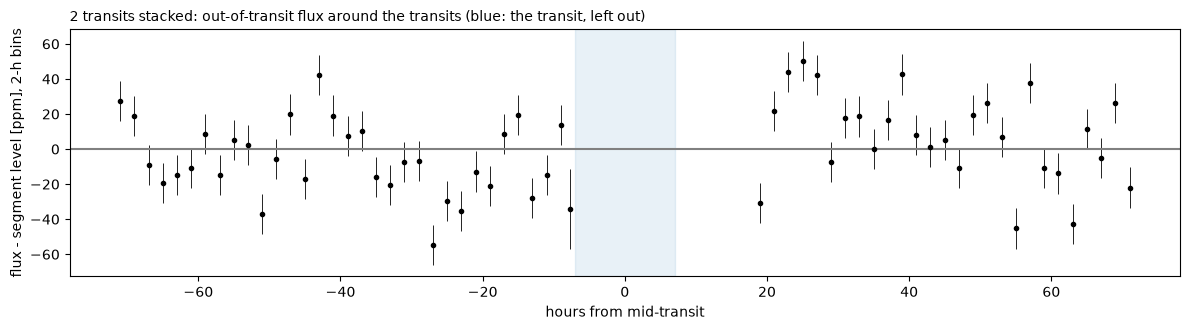

In [17]:
# all transits stacked: is there a systematic tied to the transits? (lc_a: its moon dip after the second transit is
# left out with skip=..., see texts)
fig = blind.plot_post_transit(t, f, sigma, T0, P, T14, [T0 + P * e for e in ft["epoch"]], bad=bad,
                              skip=SKIP_STACK if "SKIP_STACK" in globals() else None)
plt.show()

**The two detrenders agree around the first transit**: both trends stay within ±20 ppm of the out-of-transit level,
with identical residuals.

**Around the second transit they differ, because of the moon.** The moon's dip after egress (+7 to +15 h) lies outside
the planet's transit mask (±7 h). The GP's trend, predicted from the out-of-transit data, follows it down by ~80 ppm,
and the biweight, robust to it, rises by ~25 ppm. In the fits the moon model takes the dip: the biweight trend is
fixed before the fit (and has not absorbed the dip, section 5), the GP is fitted together with the planet and moon.
The stack below leaves the moon's dip (+0.2 to +0.75 d) out.

**Post-transit brightening (all six light curves).** In the one to two days after each transit the flux is higher than
the segment level by ~10–20 ppm (lc_a: two transits, noisy), fading within ~40 h; before the transits the level is
normal; at random times the same comparison gives −0.6 ± 0.4 ppm. It looks like an instrumental or processing memory
effect, not like anything a star, planet or moon does; neither detrender models it. It is ~20× smaller than the moon's
dip and does not affect the detection.

### 8.2 The transits with the best planet-only and planet+moon models

As in the characterisation tutorial: one column per transit, the data (grey: 10-min, black: 1-h bins) with the
best-fit planet-only (blue) and planet+moon (red) models. Below: the data minus the planet of the planet+moon fit (its
planet component), with the moon's own transit in that fit (red; it can only dim the star). This is what the moon model
attributes to the moon: where the black points follow the red curve, the data contain the moon's dip.

In [18]:
jk = r_gp["jackknife"]
order = np.argsort(jk["dchi2_epochs"])[::-1]
show = sorted(np.array(jk["epochs"])[order[:6]])          # at most 6 transits: those where the moon matters most
tmids = [T0 + P * e for e in show]
PLOT_HALF = min(HALF, 2.5 * T14 + 0.25)     # half-width of the transit plots [d]

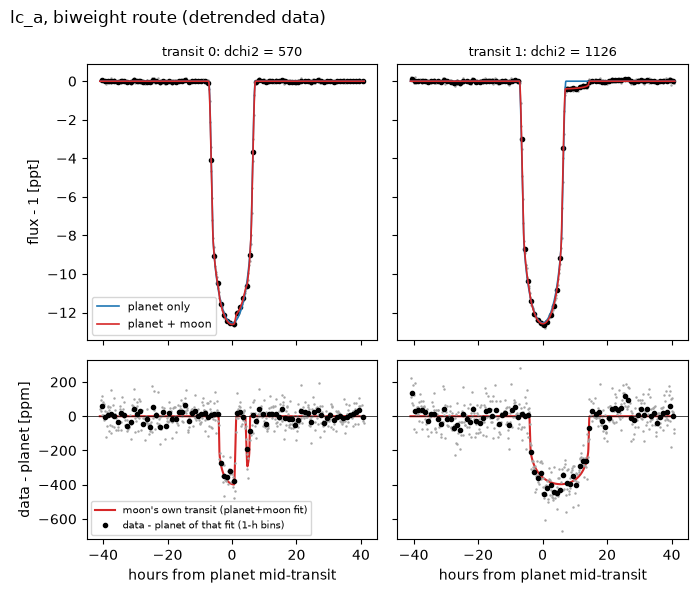

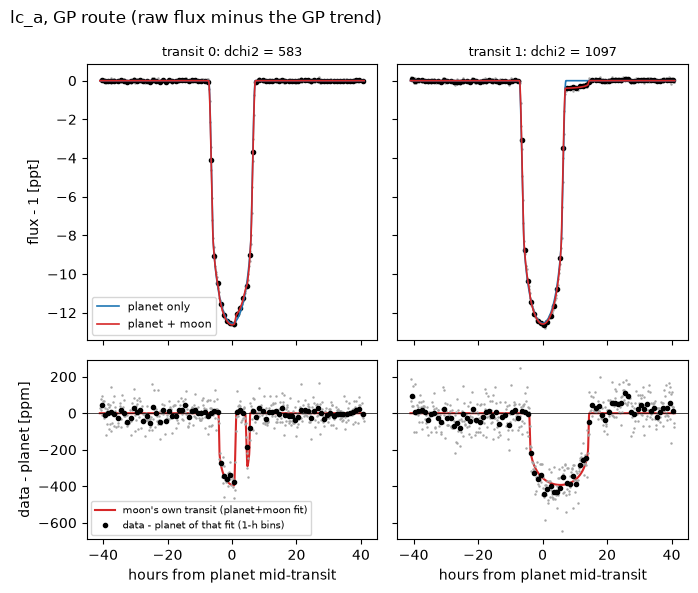

In [19]:
for lab, s, r in (("biweight", s_bw, r_bw), ("GP", s_gp, r_gp)):
    tg, gm, gpl, gpc = blind.model_on_grid(s, tmids, PLOT_HALF)
    jk = r["jackknife"]
    dch = dict(zip(jk["epochs"], jk["dchi2_epochs"]))
    labels = [f"transit {e}: dchi2 = {dch.get(e, np.nan):.0f}" for e in show]
    if lab == "biweight":
        tc, data, fm, fp = blind.best_models(s)
        fpc = blind.best_planet_component(s)
        blind.plot_transits(tc, data, fm, fp, tmids, labels, halfwidth=PLOT_HALF, model_time=tg, model_moon=gm,
                            model_planet=gpl, f_planet_comp=fpc, model_planet_comp=gpc,
                            title=f"lc_{NAME}, biweight route (detrended data)")
    else:
        blind.plot_transits(gpw["time"], gpw["flux"] - tr_gp["mu_moon"], tr_gp["f_moon"], tr_gp["f_planet"], tmids,
                            labels, halfwidth=PLOT_HALF, model_time=tg, model_moon=gm, model_planet=gpl,
                            f_planet_comp=tr_gp["f_planet_comp"], model_planet_comp=gpc,
                            title=f"lc_{NAME}, GP route (raw flux minus the GP trend)")
    plt.show()

**What the models do.** Top: the planet-only model (blue) misses the moon's dip after the second transit's egress (right); the planet+moon model (red) follows it. Bottom: the moon's own transit in the planet+moon fit. In the second transit it is a ~400 ppm dip from mid-transit to +15 h: the moon crosses the star several hours after the planet. In the first transit the moon crosses the star together with the planet (in front of or behind it), with two short gaps where the two bodies overlap. In both transits the data minus the planet follow the moon's transit: the dip is in the data, not only in the model. The GP route gives the same picture.

### 8.3 Residuals of the best planet+moon model: spots, artefacts, a wrong transit shape?

If the planet+moon model describes the data, its residuals are noise. Synthetic star spots crossed by the planet would
show as bumps *inside* the transit, a wrong limb-darkening law or exposure time as a pattern at ingress and egress,
and instrumental dips as structure outside. χ²/N compares the residuals with the error bars (for the GP route: the
white-noise part, σ(t) × err_scale, after subtracting the GP trend).

biweight: residuals of the best planet+moon model (chi2/N: 1 = as expected from the error bars)
   transit time   chi2/N in transit   chi2/N outside   mean in-transit residual [ppm]
        4.999          0.95              0.88          +14.3 +- 6.7
      370.247          1.07              0.95          -19.8 +- 9.4
GP: residuals of the best planet+moon model (chi2/N: 1 = as expected from the error bars)
   transit time   chi2/N in transit   chi2/N outside   mean in-transit residual [ppm]
        4.999          0.96              0.90          +11.7 +- 5.8
      370.247          1.23              1.14          -18.6 +- 8.1


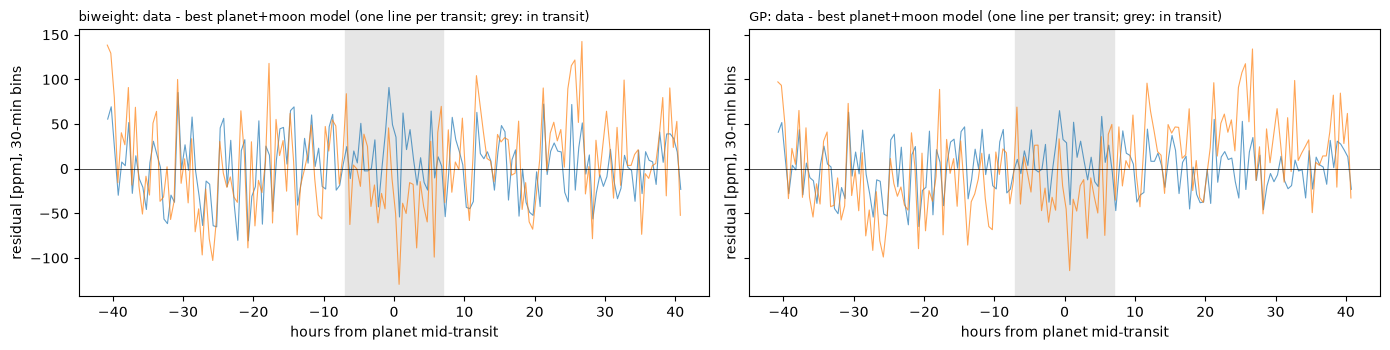

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
tc, data, fm, fp = blind.best_models(s_bw)
lc_err = np.interp(tc, bw["time"], bw["flux_err"])
res_rows_bw = blind.residual_check(tc, data - fm, lc_err, [T0 + P * e for e in ft["epoch"]], T14, PLOT_HALF,
                                   label="biweight", ax=axs[0])
res_rows_gp = blind.residual_check(gpw["time"], gpw["flux"] - tr_gp["mu_moon"] - tr_gp["f_moon"],
                                   gpw["flux_err"] * gp.err_scale, [T0 + P * e for e in ft["epoch"]], T14, PLOT_HALF,
                                   label="GP", ax=axs[1])
plt.tight_layout()
plt.show()

**The residuals of the planet+moon model are noise.** χ²/N is 0.88–1.23 inside and outside the transits in both
routes. The mean in-transit residuals are +14 ± 7 and −20 ± 9 ppm (biweight; GP: +12 ± 6, −19 ± 8), at the 2σ level
and of opposite sign: no spot crossings, no systematic misfit of the transit shape.

### 8.4 Posteriors: the moon

Corner plot of the moon's parameters, both routes (blue: biweight, red: GP). r_moon in stellar radii, per_moon in
days, M_moon / M_planet, the inclination i_moon and orientation Ω_moon [deg] of the moon's orbit, and its phase
tau_moon at the first transit. Ω is folded to 0–180° (Ω and Ω + 180° give the same light curves at the transits).

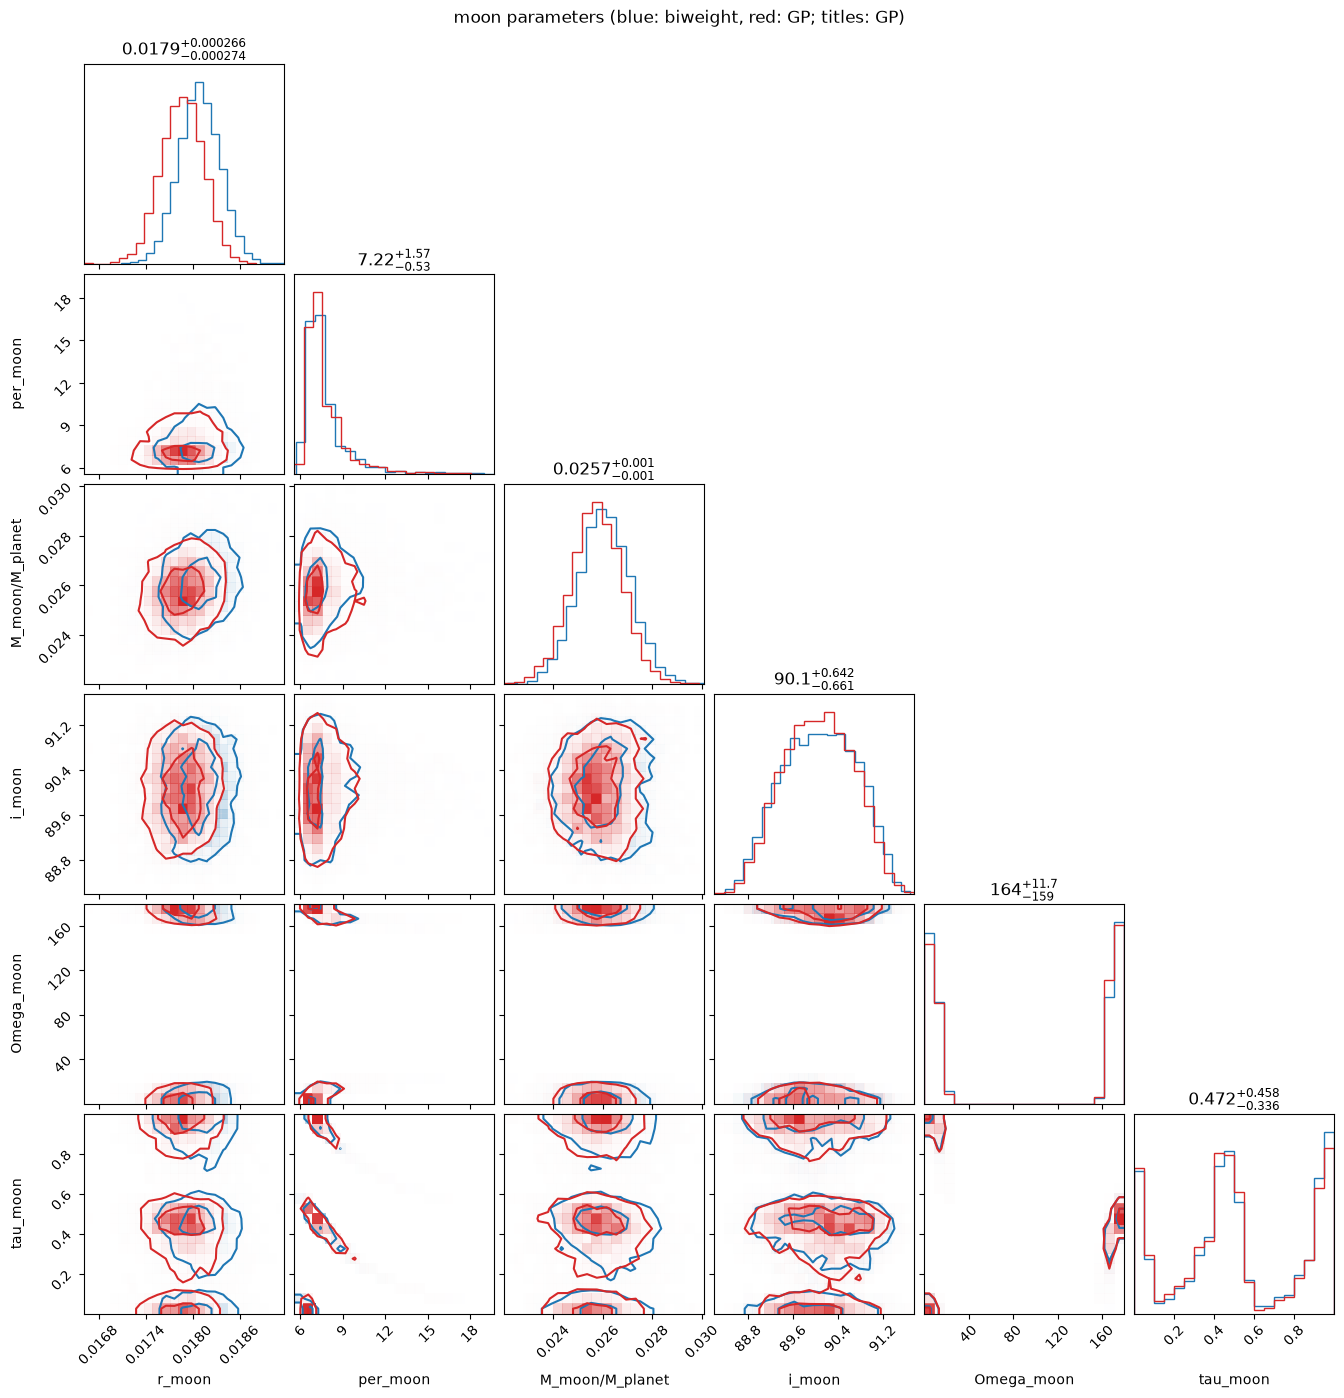

In [21]:
import corner
S_bw, S_gp = blind.samples_dict(r_bw), blind.samples_dict(r_gp)
keys = ["r_moon", "per_moon", "M_moon/M_planet", "i_moon", "Omega_moon", "tau_moon"]
hk = dict(density=True)
fig = corner.corner(np.column_stack([S_bw[k] for k in keys]), labels=keys, color="C0", hist_kwargs=dict(hk, color="C0"),
                    plot_datapoints=False, levels=(0.393, 0.865))
corner.corner(np.column_stack([S_gp[k] for k in keys]), fig=fig, color="C3", hist_kwargs=dict(hk, color="C3"),
              plot_datapoints=False, levels=(0.393, 0.865), show_titles=True, title_fmt=".3g")
fig.suptitle("moon parameters (blue: biweight, red: GP; titles: GP)", y=1.01)
plt.show()

**The moon.** Both routes agree on every parameter:

- **radius** r_moon = 0.0181 ± 0.0003 stellar radii (a 320 ppm dip), measured to 1.5 %;
- **period** 7.2 d (6.7–8.8 d, 68 %) with a tail to ~12 d. With two transits, the moon's position is known at two
  times only; periods that put it at the same two places are aliases;
- **mass ratio** M_moon / M_planet = 0.026 ± 0.001: measured through the planet's wobble (duration and shape changes
  of its transit);
- **orientation:** i_moon = 90.1 ± 0.7° and Ω ≈ 0° (= 180°): the moon's orbit is seen edge-on and lies in the
  planet's orbital plane;
- **phase** tau_moon: two modes half an orbit apart: at the first transit the moon was in front of or behind the
  planet. The light curve cannot tell which.

### 8.5 Posteriors: planet and star in the planet+moon model

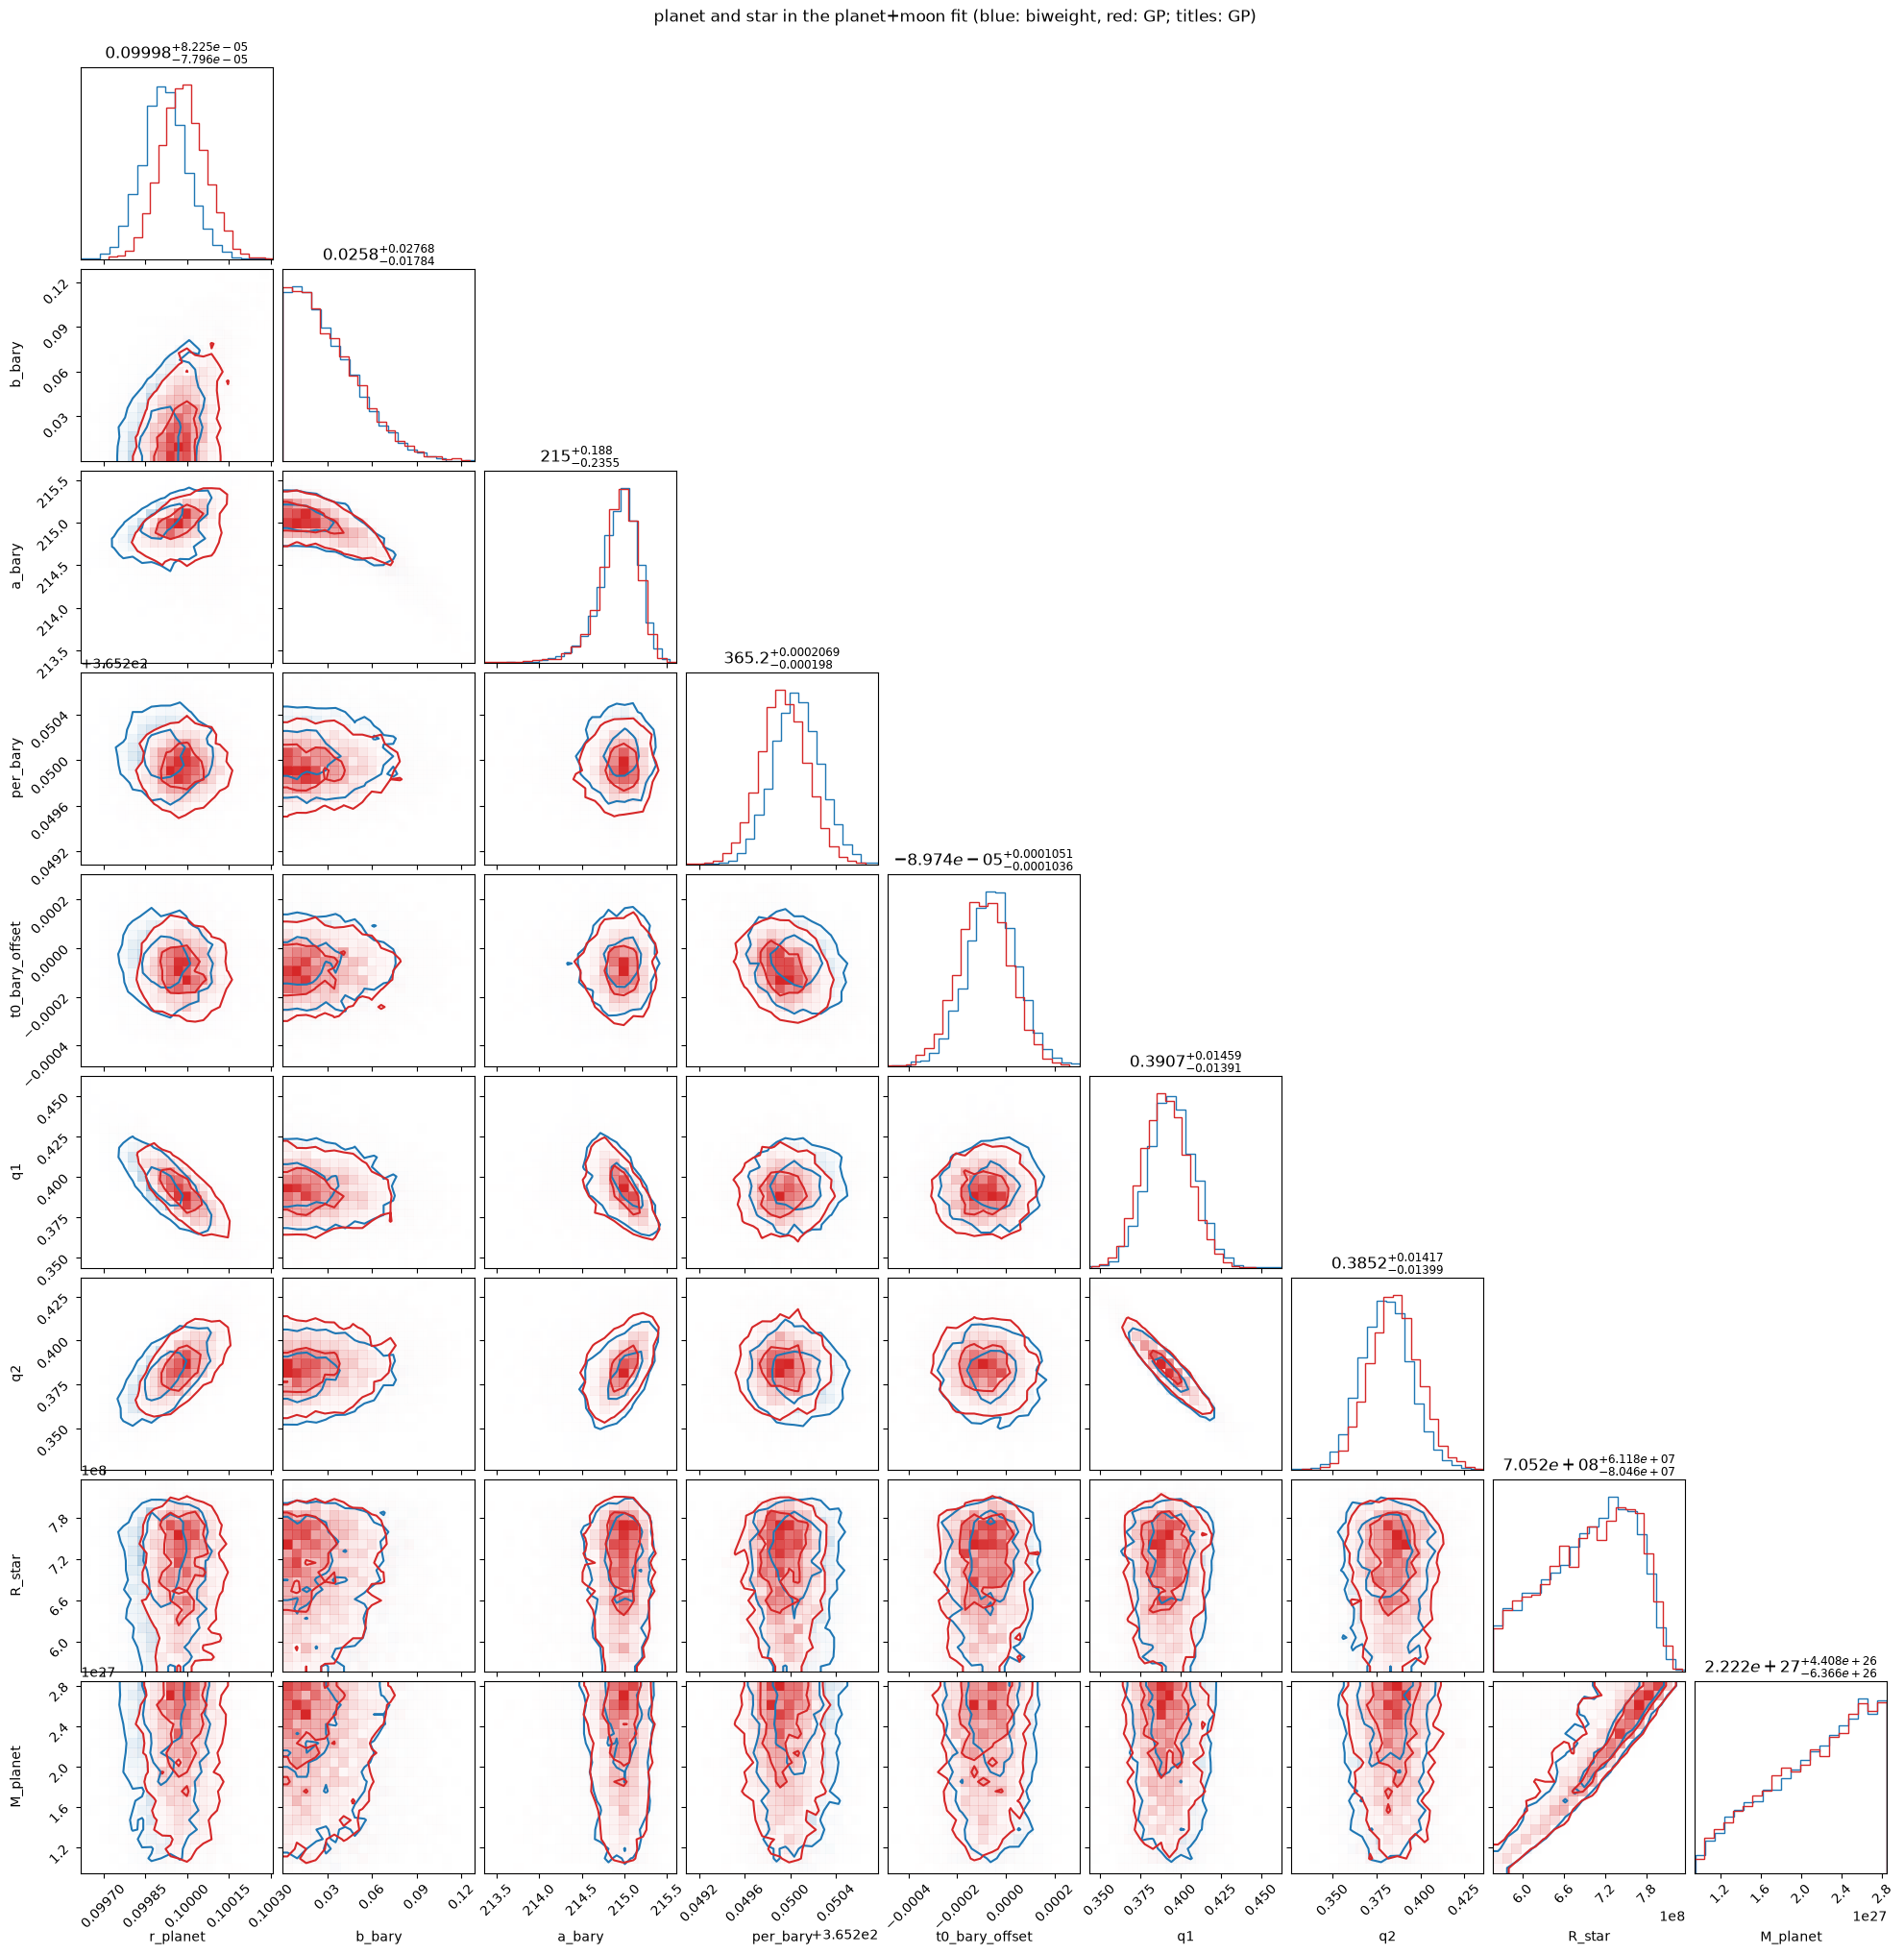

In [22]:
keys = ["r_planet", "b_bary", "a_bary", "per_bary", "t0_bary_offset", "q1", "q2", "R_star", "M_planet"]
fig = corner.corner(np.column_stack([S_bw[k] for k in keys]), labels=keys, color="C0", hist_kwargs=dict(hk, color="C0"),
                    plot_datapoints=False, levels=(0.393, 0.865))
corner.corner(np.column_stack([S_gp[k] for k in keys]), fig=fig, color="C3", hist_kwargs=dict(hk, color="C3"),
              plot_datapoints=False, levels=(0.393, 0.865), show_titles=True, title_fmt=".4g")
fig.suptitle("planet and star in the planet+moon fit (blue: biweight, red: GP; titles: GP)", y=1.01)
plt.show()

**Planet and star.** The planet's radius (0.1000 ± 0.0001 stellar radii), impact parameter (0.03, < 0.08: a central
transit) and limb darkening are measured precisely, and both routes agree. Two parameters are **not measured**:
R_star and M_planet run into the edges of their priors (0.8–1.2 R_sun, 0.5–1.5 M_jup) and are tightly correlated.
The light curve gives the moon's orbit in units of the stellar radius, so Kepler's law for the moon fixes only the
combination M_planet / R_star³. The absolute masses and radii in section 9 therefore depend on the prior on R_star;
the **densities** do not (section 9).

### 8.6 Posteriors: the GP's trend parameters

The fit holds the GP's hyperparameters fixed at their `GP.fit` values. How well do the data constrain them? A short
Metropolis chain over (amp, tau, err_scale) on the residuals of the best planet+moon model in the fit windows
(log-uniform priors over `GP.fit`'s bounds) shows their posterior. `gp_profile` (section 6) refits them for each model.

Metropolis acceptance 0.27; GP.fit values: amp 20.3 ppm, tau 10.0 min, err_scale 0.996
amp 38.9 ppm (68 %: 35.5 ... 42.1); tau median 12 min; err_scale 1.012


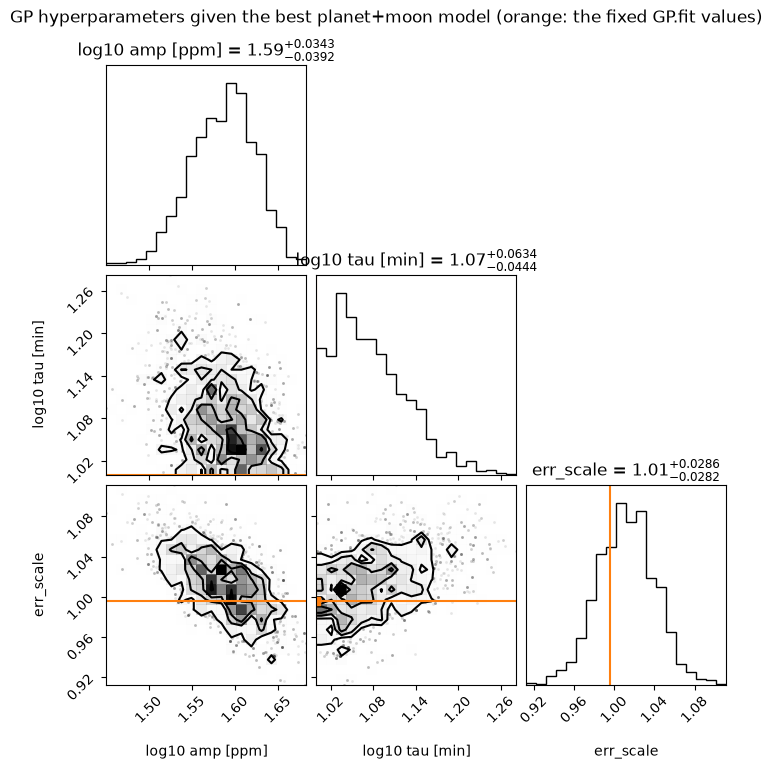

gp_profile: {'dlogz': 162.30142952035885, 'dlogzerr': 0.198741826882978, 'dlogz_fixed': 802.6202103417165, 'ess_moon': 159.39718669635474, 'seconds': 18.5049296929501}


In [23]:
resid1 = gpw["flux"] - tr_gp["f_moon"] + 1.0
post = blind.gp_posterior(gp, gpw["time"], resid1, gpw["flux_err"], n_steps=6000, n_burn=1500)
print(f"Metropolis acceptance {post['acceptance']:.2f}; GP.fit values: amp {1e6 * gp.amp:.1f} ppm, "
      f"tau {1440 * gp.tau:.1f} min, err_scale {gp.err_scale:.3f}")
# log axes: where the data constrain the GP weakly, the chain spreads over orders of magnitude
X = np.column_stack([np.log10(1e6 * post["amp"]), np.log10(1440 * post["tau"]), post["err_scale"]])
fig = corner.corner(X, labels=["log10 amp [ppm]", "log10 tau [min]", "err_scale"], show_titles=True,
                    title_fmt=".3g", truths=[np.log10(1e6 * gp.amp), np.log10(1440 * gp.tau), gp.err_scale],
                    truth_color="C1")
lo, med, hi = np.percentile(post["amp"], [16, 50, 84]) * 1e6
print(f"amp {med:.1f} ppm (68 %: {lo:.1f} ... {hi:.1f}); tau median {1440 * np.median(post['tau']):.0f} min; "
      f"err_scale {np.median(post['err_scale']):.3f}")
fig.suptitle("GP hyperparameters given the best planet+moon model (orange: the fixed GP.fit values)", y=1.02)
plt.show()
if r_gp.get("gp_profile"):
    print("gp_profile:", {k: v for k, v in r_gp["gp_profile"].items() if not hasattr(v, "__len__") or isinstance(v, str)})

**The GP's hyperparameters in the fit windows** (given the best planet+moon model): amplitude 39 ppm (35–42), time
scale ~12 min, white-noise factor 1.01, against 20 ppm, 10 min and 0.996 from `GP.fit` outside the windows. The two
describe the same short-scale correlated noise (amplitude and white-noise factor are degenerate); the total short-scale
variance is a few per cent larger in the windows. `gp_profile` accounts for this for both models.

## 9. The physics of the planet+moon solution

From the posterior samples (GP route): the star's mass follows from a_bary, per_bary and R_star (Kepler's third law),
the moon's orbit from its period and the masses. Radii and masses in Earth and Jupiter units, densities, the moon's
orbit in planet radii and as a fraction of the planet's Hill radius, the Roche limit, and the planet's timing wobble.

In [24]:
Q = blind.physics(S_gp)
blind.print_physics(Q)

  M_star [M_sun]                                                      1.041   (68 %: 0.7203 ... 1.336)
  R_star [R_sun]                                                      1.013   (68 %: 0.8966 ... 1.101)
  rho_star [g/cm^3]                                                   1.408   (68 %: 1.404 ... 1.412)
  a_bary [AU]                                                         1.013   (68 %: 0.8964 ... 1.101)
  R_planet [R_jup]                                                   0.9861   (68 %: 0.8732 ... 1.072)
  R_planet [R_earth]                                                  11.07   (68 %: 9.798 ... 12.03)
  M_planet [M_jup]                                                    1.171   (68 %: 0.8336 ... 1.404)
  rho_planet [g/cm^3]                                                 1.401   (68 %: 1.302 ... 1.691)
  R_moon [R_earth]                                                    1.979   (68 %: 1.75 ... 2.146)
  M_moon [M_earth]                                                    9.549   

**The system** (GP route; the biweight route gives the same within the errors):

- **The star** has a mean density of 1.408 g cm⁻³ (68 %: 1.404–1.412), the Sun's (1.41). The transit measures it
  directly (a/R★ = 214.9 and P = 365.25 d). With the prior's radius of 0.8–1.2 R_sun it is a Sun-like star; the planet
  orbits at 1 AU.
- **The planet:** 0.99 R_jup (11.1 R_earth), a density of 1.40 g cm⁻³ (Jupiter: 1.33); its mass, ~1.2 M_jup, is set by
  the prior.
- **The moon:** **2.0 R_earth** (1.75–2.15) and **9.6 M_earth** (6.8–11.5), mass ratio 0.026. Its density, **6.4 g cm⁻³**
  (5.8–7.6), is well determined because it does not depend on the stellar radius: a rocky, iron-rich super-Earth,
  denser than Earth (5.5).
- **The orbit:** a 7.2-day period at 1.15 million km = 16 planetary radii, or **0.11 Hill radii**: deep inside the
  stability limit for prograde moons (~0.5 Hill radii) and 11× outside the Roche limit. On the sky the moon reaches up
  to ±10 h of transit time from the planet; in the second transit it trailed the planet by ~8 h.
- **The planet's wobble:** up to 16 min of transit time (TTV). With two transits a TTV cannot be separated from the
  period, but the matching change of the transit's duration is visible (section 2).

A moon with 2.6 % of its planet's mass is far heavier than any moon in the solar system (Titan: 0.02 %, the Moon: 1.2 %
of Earth). Moons of this mass ratio do not form in a circumplanetary disk (which yields ~10⁻⁴); they would need a
capture or a giant impact.

## 10. Further checks: audit and injection-retrieval tests

Four of the six blind light curves gave no moon, so we searched for errors in our own analysis, in two ways:

- an **audit**: cheap checks of each step and assumption (priors, fit windows, noise, detrending, transit model);
- **injection-retrieval tests**: synthetic moons are inserted into the real light curve, the light curve is analysed
  again exactly as in this notebook, and we count how many moons are found.

**What the audit found, for all six light curves:**

- **Priors:** no moon parameter piles up at the upper edge of its prior (radius, period, mass) in any fit, so the data
  do not ask for larger, wider or heavier moons than allowed. Pile-ups at lower edges are expected: the impact
  parameter at 0 (central transits) and, in the no-moon fits, the shortest moon periods (the "hiding places" inside
  the Roche limit).
- **Fit windows:** fully covered by data in every light curve, and no significant dip just outside them (searched out
  to the Hill radius of a 1.5 Jupiter-mass planet).
- **Noise:** the noise σ(t) must be estimated with the transits masked; otherwise the steep ingress and egress
  inflate it by 15–23 % near deep transits (our first round of fits had this bias and was redone). With the mask, the
  errors are calibrated (χ²/N = 0.9–1.04 near the transits).
- **Transit model:** the stacked planet-only residuals show no pattern at ingress, egress or the transit bottom;
  quadratic limb darkening and 10-minute exposures (5 sub-exposures) are adequate at this precision.
- **Detrending:** the biweight keeps deep moon dips (300 ppm: 88–100 % of the dip), but removes 25–30 % of a
  shallow (80 ppm) dip that lasts as long as the transit, i.e. 40–50 % of its Δχ². The GP with its fitted 10-minute
  time scale keeps 62–86 % of a dip's evidence; slower GPs (as in the conservative Bayes factor) keep only 6–13 %,
  which is why the conservative value is a lower bound.
- **`detect` setting:** at its default `recall=0.95`, `detect` sometimes misses the moon model's mode (lc_b). With
  `recall=0.999` (a few seconds more) repeated runs agree; we used it for all injection tests.
- **Two signals no model includes:** a **post-transit brightening** (+5 to +20 ppm for ~40 hours after every transit,
  in all six light curves; it can cancel part of a trailing moon's dip), and a **slow deepening of the transits**
  (most light curves by ~0.2 % per year). A transit that changes with time favours the planet+moon model, because the
  planet-only model has one fixed transit shape.

**A null model for a changing transit.** Pandora's planet-only model has one transit depth for all transits. As a
check, we fitted the biweight data of each light curve (maximum likelihood) with the best planet-only transit whose
depth changes linearly with time (one extra parameter), and with a free depth for each transit, and compared them with
the planet+moon model (nine extra parameters). Δ BIC = Δχ² − (extra parameters) × ln N; positive favours the model
over the planet with a fixed transit:

| light curve | transits | depth change per year | Δχ² linear depth (1) | Δχ² free depth per transit | Δχ² planet+moon (9) | Δ BIC linear depth | Δ BIC planet+moon |
|---|---|---|---|---|---|---|---|
| lc_a | 2 | +0.56 % | 26 | 26 | 1696 | +19 | +1630 |
| lc_b | 8 | +0.46 % | 168 | 198 | 193 | +160 | +124 |
| lc_c | 2 | +0.35 % | 13 | 13 | 25 | +6 | −42 |
| lc_d | 8 | +0.20 % | 12 | 24 | 27 | +4 | −42 |
| lc_e | 2 | +0.28 % | 0.3 | 0.3 | 12 | −6 | −49 |
| lc_f | 32 | +0.43 % | 6 | 51 | 34 | −2 | −37 |

Only lc_a's moon beats a changing transit by far; in lc_c and lc_d a slow deepening explains half of the moon model's
small improvement. (For lc_b the planet+moon fit did not converge; its section 10 shows that timing variations add to
the picture.) **Transit timing:** fitted transit by transit with the planet's own shape, the mid-times of lc_d
(8 transits, ±0.12 min) and lc_f (32 transits, ±0.4 min) scatter close to their errors (χ² 18 for 7 degrees of
freedom, a mild excess of ±0.2 min, and 36 for 31); only lc_b shows strong timing variations (χ² 142 for 7, ±0.48 min).
With two transits (lc_a, lc_c, lc_e) a timing variation cannot be told apart from the period.

**Audit items specific to lc_a.**

- **The moon is far above every sensitivity limit we measured.** In the injection tests on the four light curves
  without a moon (lc_c–f), half of the moons are found at 0.55–0.85 R_earth and 90 % at 0.7–1.2 R_earth; a 2 R_earth
  moon like lc_a's is found in 99–100 % of the injections in every one of them.
- **The two signals no model includes** do not explain the moon: the post-transit brightening (+5 to +20 ppm) is
  ~20× smaller than the moon's dip (~340 ppm), and of the opposite sign; and lc_a's transit changes in a way a slow
  drift cannot produce: the duration changes by ~10 minutes between the two transits (the planet's wobble, section 2),
  while the other light curves' transits keep their durations to within ~2 minutes.
- **lc_a's moon is not in lc_c**, the light curve with the most similar planet: placed around lc_c's planet, lc_a's
  moon configurations make the fit worse by Δχ² 900–1100 (lc_c notebook, section 10). The detection is specific to
  this light curve.

## 11. Assessment, and what we learned

### Assessment

**lc_a contains a moon.** The evidence is decisive in every estimate: Δln Z = +811 (biweight), +803 (GP, fixed
hyperparameters), +162 (GP, conservative). We quote the conservative value. Five independent checks agree:

1. the moon's dip after the second transit is visible in the raw data without a model (section 2),
2. the first transit shows the duration and shape changes a moon causes, while its dip is hidden behind or in front of
   the planet; the jackknife confirms that both transits carry the signal,
3. both detrending routes give the same moon (radius, period, mass ratio, orientation),
4. the solution is physical: a coplanar, edge-on, prograde orbit at 0.11 Hill radii, a rocky density,
5. the alternatives do not fit: a star spot is a bump, not a dip; an instrumental dip would not come with the duration
   change; another transiting body on the same orbit would show in both transits; the post-transit brightening is
   ~20× too small and of the opposite sign.

**Identified system:** a Sun-like star (ρ★ = 1.41 g cm⁻³), a Jupiter-size planet (0.99 R_jup, ρ 1.4 g cm⁻³) on a
one-year orbit at 1 AU, and a moon of **2.0 R_earth, 9.6 M_earth (ρ 6.4 g cm⁻³)** on a **7.2-day** orbit (alias tail to
~12 d) in the planet's orbital plane.

**Caveats:** only two transits (the period is aliased; the moon's phase has two modes); the absolute radii and masses
scale with the assumed stellar radius; the evidences are uncertain by ~1 nat because the fits did not pass all
convergence checks.

### Step by step: what worked, and what we learned

1. **Look at the raw data first.** Ramps at the segment edges (±20–40 ppm), a noise level that changes by 2× between
   quarters, correlated neighbouring points (+0.11), and a brightening after every transit: none is visible in a quick
   plot, all are at the moon's level of tens to hundreds of ppm.
2. **Estimate the noise without the transits.** A point-to-point noise estimate that includes a deep transit's ingress
   and egress is 15–23 % too high near the transits; our first round of fits used such errors and underestimated
   every Bayes factor.
3. **Use per-point error bars** where the noise changes with time, and measure β on all out-of-window data.
4. **Compute the moon's reach from the prior** and make the fit windows at least that wide (here ±2.75 d).
5. **Subtract the transits from each other before fitting.** The difference showed the moon's dip and the duration
   change at once.
6. **`detect` answers "is there something?" in seconds**; use `recall=0.999` when it matters (the default can miss a
   clear moon's mode), and the full fit for the moon's properties.
7. **Two-transit moons are hard for the sampler**: 20–35 G likelihood calls, 31 min (biweight) and 76 min (GP) on an
   RTX 5060, with live points and chains escalated to their caps. Run one GPU fit at a time on an 8-GB card: a second
   one crashed with out-of-memory.
8. **With a GP, quote the conservative Bayes factor** (`gp_profile=True`): 162 instead of 803.
9. **Quote what the data measure**: densities, the mass ratio, the moon's orbit in Hill radii.

## Reproducibility

The run times and versions of this notebook's fits:

In [25]:
import platform
for lab, r in (("biweight", rec_bw), ("GP", rec_gp)):
    print(f"{lab:9s}: planet+moon fit {r['wall'] / 60:6.1f} min, {r['ncall'] / 1e9:.2f} G likelihood calls, "
          f"n_live {r['nlive']}, nsteps {r['nsteps']}, status {r['status']} ({r['date']})")
print("detect wall time: biweight %.1f s, GP %.1f s" % (det_bw["wall"], det_gp["wall"]))
print(platform.platform(), "| python", platform.python_version())
try:
    import numba.cuda
    print("GPU:", str(numba.cuda.get_current_device().name) if numba.cuda.is_available() else "none")
except Exception as e:
    print("GPU: not available", e)

biweight : planet+moon fit   31.3 min, 19.79 G likelihood calls, n_live 2000, nsteps 128, status stalled (2026-11-21T11:31:17)
GP       : planet+moon fit   76.0 min, 34.64 G likelihood calls, n_live 2000, nsteps 256, status stalled (2026-11-21T13:14:19)
detect wall time: biweight 18.3 s, GP 16.9 s
Linux-6.1.0-54-amd64-x86_64-with-glibc2.36 | python 3.12.2


GPU: NVIDIA GeForce RTX 5060
